# The kinds of composition on the paper's toy data, and how each sampler handles them

This is the worked example for claims 4 and 8 of [the overlap-dial idea map](IDEA_MAP.md), with the kinds defined in [the composition terms](composition-terms.md). It uses the 2D toy datasets of Du et al. 2023 (`notebooks/simple_distributions.ipynb`).

**Figure 1 asks how well each sampler reaches each kind**, one row per kind at a setting where the composition succeeds:

`p1 | p2 | exact composition | a perfect sampler | reverse diffusion | annealed ULA | annealed MALA | annealed UHA`

**Figure 2 asks which condition makes a kind succeed**: the exact composition's success measure against one dial, for the kinds where a condition decides it.

**Why every error here is measurable.** Each expert is an ideal expert: its training points smoothed by $\mathcal{N}(0, \sigma^2 I)$, $\sigma = 0.05$, the optimum a diffusion model reaches (run 2 showed trained 2D networks match it within `0.04` nats). Its noised density at every diffusion step is then exact:

$$q_t(x) = \frac{1}{N}\sum_{i=1}^{N} \mathcal{N}\!\big(x;\ \sqrt{\bar\alpha_t}\,x_i,\ (1 - \bar\alpha_t + \bar\alpha_t\sigma^2) I\big).$$

So the samplers run on exact scores and energies, and the target is computed exactly on a $241 \times 241$ grid. **Any gap between a sampler's samples and the exact composition is the sampler's error and nothing else.** The "perfect sampler" column draws the same number of points straight from the exact grid density, so it shows how far 2,000 points sit from the target even with no sampler error.

In [1]:
import os, sys, subprocess, numpy as np, torch, matplotlib.pyplot as plt
sys.path.insert(0, os.path.abspath("../../.."))            # repo root, for anneal_samplers.py
from anneal_samplers import AnnealedULASampler, AnnealedUHASampler
plt.rcParams.update({"figure.dpi": 100, "axes.titlesize": 8})

def pick_device():   # GPU guard (execution protocol): first card under 1 GB in use, else CPU
    try:
        rows = subprocess.run(["nvidia-smi", "--query-gpu=index,memory.used", "--format=csv,noheader,nounits"],
                              capture_output=True, text=True, timeout=10).stdout.strip().splitlines()
        for r in rows:
            i, used = (int(v) for v in r.split(","))
            if used < 1024 and torch.cuda.is_available(): return torch.device(f"cuda:{i}")
    except Exception: pass
    return torch.device("cpu")
dev = pick_device(); print("device:", dev, "| node:", os.uname().nodename)

rng = np.random.default_rng(0); torch.manual_seed(0)
L, G, SIG, N, NS = 1.1, 241, 0.05, 800, 2000          # canvas, grid, smoothing, points per expert, samples
xs = np.linspace(-L, L, G); X1, X2 = np.meshgrid(xs, xs); cell = (xs[1] - xs[0]) ** 2
grid_t = torch.tensor(np.stack([X1.ravel(), X2.ravel()], 1), dtype=torch.float32, device=dev)

# the notebook's cosine schedule, 100 steps
T = 100
def cosine_betas(T, s=0.008):
    x = np.linspace(0, T, T + 1); ac = np.cos(((x / T) + s) / (1 + s) * np.pi * 0.5) ** 2
    return np.clip(1 - ac[1:] / ac[:-1], 0, 0.999)
betas = cosine_betas(T); alphas = 1 - betas; abar = np.cumprod(alphas)

def logq(x, data, t):
    "Exact log-density of the ideal expert at diffusion step t (t = -1 means no diffusion)."
    a = 1.0 if t < 0 else abar[t]
    v = (1 - a) + a * SIG**2
    d2 = torch.cdist(x, np.sqrt(a) * data) ** 2
    return torch.logsumexp(-d2 / (2 * v), 1) - np.log(len(data)) - np.log(2 * np.pi * v)

def exact_grid(kind):
    A, B = kind["data"]
    with torch.no_grad():
        lp = kind["compose"](logq(grid_t, A, -1), logq(grid_t, B, -1)).reshape(G, G).cpu().numpy().astype(np.float64)
    p = np.exp(lp - lp.max()); return p / (p.sum() * cell)

def perfect_samples(p, n=NS):
    "n points drawn straight from the exact grid density (no sampler error)."
    w = (p * cell).ravel(); idx = rng.choice(len(w), n, p=w / w.sum())
    pts = np.c_[X1.ravel()[idx], X2.ravel()[idx]]
    return pts + rng.uniform(-0.5, 0.5, pts.shape) * (xs[1] - xs[0])

# total variation distance between samples and the exact density, on a 40 x 40 binning of the canvas
EDGES = np.linspace(-L, L, 41)
def tv(samples, p):
    pb = np.histogram2d(X2.ravel(), X1.ravel(), [EDGES, EDGES], weights=(p * cell).ravel())[0]
    sb = np.histogram2d(samples[:, 1], samples[:, 0], [EDGES, EDGES])[0] / len(samples)
    return 0.5 * np.abs(pb / pb.sum() - sb).sum()

device: cuda:0 | node: mscluster109.ms.wits.ac.za


## The samplers

**Reverse diffusion with the composed score.** The DDPM step $x_{t-1} = \frac{1}{\sqrt{\alpha_t}}\big(x_t + \beta_t\, s_t(x_t)\big) + \sqrt{\tilde\beta_t}\, z$, where $s_t$ is the score of the composed noised densities, for example $\nabla \log q^A_t + \nabla \log q^B_t$ for a product. Du et al. 2023 (p.4, eqs. 11 and 12) show this does not sample the product, because the product of two noised densities is not the noised product.

**Annealed MCMC** targets $\pi_t(x) \propto$ the composed noised densities at each step $t$, from $t = 99$ down to $0$, with 10 moves per step, starting from $\mathcal{N}(0, I)$. Because each $\pi_t$ is targeted directly, the last one is the exact composition.

- **ULA** (Langevin, no accept step): `AnnealedULASampler` from `anneal_samplers.py`, unchanged.
- **MALA** (Langevin plus a Metropolis accept step): written here, because `anneal_samplers.py`'s version has two bugs. Its proposal log-density divides by `2*ss**2` where the proposal variance is `2*ss` (the right divisor is `4*ss`), and it accepts or rejects the whole batch with one random number. This version accepts each sample on its own.
- **UHA** (Hamiltonian moves with partial momentum refresh, no accept step): `AnnealedUHASampler` from `anneal_samplers.py`, unchanged, with the notebook's damping `0.5` and `3` leapfrog steps.

Step sizes scale with the noise variance at each step, $v_t = 1 - \bar\alpha_t + \bar\alpha_t \sigma^2$: `0.05·v_t` for ULA and MALA, and `0.3·√v_t` for UHA.

In [2]:
def energy_fn(kind, t):
    A, B = kind["data"]
    return lambda x: kind["compose"](logq(x, A, t), logq(x, B, t))        # log pi_t, up to a constant

def grad_fn(kind, t):
    f = energy_fn(kind, t)
    def g(x):
        x = x.detach().requires_grad_(True)
        return torch.autograd.grad(f(x).sum(), x)[0].detach()
    return g

def reverse_diffusion(kind):
    x = torch.randn(NS, 2, device=dev)
    for t in range(T - 1, -1, -1):
        s = grad_fn(kind, t)(x)
        var = betas[t] * (1 - (abar[t - 1] if t > 0 else 1.0)) / (1 - abar[t])
        x = (x + betas[t] * s) / np.sqrt(alphas[t])
        if t > 0: x = x + np.sqrt(var) * torch.randn_like(x)
    return x.cpu().numpy()

LEVELS = list(range(T - 1, -1, -1))
V = np.array([1 - abar[t] + abar[t] * SIG**2 for t in LEVELS])

def annealed(kind, which):
    x = torch.randn(NS, 2, device=dev)
    gfun = lambda x, ts: grad_fn(kind, ts)(x)
    if which == "ULA":
        s = AnnealedULASampler(T, 10, list(0.05 * V), gfun)
    else:
        s = AnnealedUHASampler(T, 10, list(0.3 * np.sqrt(V)), 0.5, [torch.ones(1, device=dev)] * T, 3, gfun)
    for i, t in enumerate(LEVELS):
        x = s.sample_step(x, i, t, {})
    return x.detach().cpu().numpy()

def annealed_mala(kind, k=10):
    "Per-sample MALA: proposal N(x + ss*g, 2*ss*I), so log q(x'|x) = -|x' - x - ss*g|^2 / (4*ss)."
    x = torch.randn(NS, 2, device=dev); acc = []
    for i, t in enumerate(LEVELS):
        f, g, ss = energy_fn(kind, t), grad_fn(kind, t), 0.05 * V[i]
        e, gr = f(x).detach(), g(x)
        for _ in range(k):
            xp = x + ss * gr + np.sqrt(2 * ss) * torch.randn_like(x)
            ep, gp = f(xp).detach(), g(xp)
            fwd = -((xp - x - ss * gr) ** 2).sum(1) / (4 * ss)
            bwd = -((x - xp - ss * gp) ** 2).sum(1) / (4 * ss)
            a = (torch.log(torch.rand(NS, device=dev)) < ep - e + bwd - fwd)
            x, e, gr = torch.where(a[:, None], xp, x), torch.where(a, ep, e), torch.where(a[:, None], gp, gr)
            acc.append(a.float().mean().item())
    return x.cpu().numpy(), float(np.mean(acc[-100:]))       # acceptance over the last 10 steps

## The seven kinds, at a setting where each succeeds

Each kind is the pair from the earlier kinds sections, at its base setting. Two settings differ from the paper. Disjunction uses $\beta = 1$, the exact mixture, because sharper $\beta$ drops the broader expert. Negation uses $w = 0.05$, because at the paper's $w = 0.3$ the exact composition already puts `0.89` of its mass away from every ring mode.

In [3]:
def toy_gmm(n, std=0.03):
    ang = 2 * np.pi * rng.integers(0, 8, n) / 8
    return 0.5 * np.c_[np.cos(ang), np.sin(ang)] + std * rng.standard_normal((n, 2))
RING = 0.5 * np.c_[np.cos(2 * np.pi * np.arange(8) / 8), np.sin(2 * np.pi * np.arange(8) / 8)]
vbar = lambda n, c=0.0, h=0.2, lo=-1.0, hi=1.0: np.c_[c + rng.uniform(-h, h, n), rng.uniform(lo, hi, n)]
hbar = lambda n, c=0.0, h=0.2, lo=-1.0, hi=1.0: np.c_[rng.uniform(lo, hi, n), c + rng.uniform(-h, h, n)]
near = lambda a, b, pts, r: np.any(np.hypot(a[..., None] - pts[:, 0], b[..., None] - pts[:, 1]) < r, -1)
def rotated(c, n, p):
    rot = rng.random(n) < p
    return np.where(rot[:, None], hbar(n, c, 0.1), vbar(n, c, 0.1))
def wet_dog(f):
    k = int(f * N)
    A = np.vstack([vbar(N - k, -0.2, 0.1, -1.0, 0.0), vbar(k, -0.4, 0.1, 0.4, 0.8)])
    B = np.vstack([hbar(N - k, 0.6), np.c_[-0.4 + rng.uniform(-0.1, 0.1, k), rng.uniform(0.4, 0.8, k)]])
    return A, B
tt = lambda a: torch.tensor(a, dtype=torch.float32, device=dev)

# a measure takes coordinates (a, b) and weights w, so it works on the grid (w = p * cell) and on samples (w = 1/n)
KINDS = [
 dict(name="intersection", data=(toy_gmm(N), vbar(N, 0.0, 0.05)), compose=lambda a, b: a + b,
      measure=lambda a, b, w: (w * near(a, b, RING, 0.08)).sum(), mname="mass on ring modes"),
 dict(name="disjunction", data=(vbar(N, -0.4, 0.1), vbar(N, 0.4, 0.2)), compose=lambda a, b: torch.logaddexp(a, b),
      measure=lambda a, b, w: (w * (a > 0)).sum(), mname="B's share"),
 dict(name="co-occurrence", data=(vbar(N, 0.0, 0.2), hbar(N, 0.6)), compose=lambda a, b: a + b,
      measure=lambda a, b, w: (w * ((np.abs(a) < 0.2) & (b > 0.4) & (b < 0.8))).sum(), mname="mass in crossing"),
 dict(name="contention", data=(rotated(-0.2, N, 0.5), rotated(0.2, N, 0.5)), compose=lambda a, b: a + b,
      measure=lambda a, b, w: (w * near(a, b, np.array([[-0.2, 0.2], [0.2, -0.2]]), 0.12)).sum(), mname="co-occurrence mass"),
 dict(name="dominance", data=(toy_gmm(N), rng.standard_normal((N, 2)) * 0.1), compose=lambda a, b: a + b,
      measure=lambda a, b, w: (w * np.hypot(a, b)).sum() / w.sum(), mname="mean radius"),
 dict(name="interaction", data=wet_dog(0.3), compose=lambda a, b: a + b,
      measure=lambda a, b, w: (w * ((b > 0.3) & (b < 0.9)) * a).sum() / (w * ((b > 0.3) & (b < 0.9))).sum(), mname="mean x1 in band"),
 dict(name="negation", data=(toy_gmm(N), vbar(N, 0.0, 0.2)), compose=lambda a, b: 1.05 * a - 0.05 * b,
      measure=lambda a, b, w: (w * near(a, b, RING[[2, 6]], 0.08)).sum(), mname="mass on the 2 in-bar modes"),
]
for k in KINDS: k["data"] = tuple(tt(d) for d in k["data"])

In [4]:
import time
COLS = ["perfect", "reverse diffusion", "ULA", "MALA", "UHA"]
results = []
t0 = time.time()
for k in KINDS:
    p = exact_grid(k); k["p"] = p
    k["exact"] = k["measure"](X1, X2, p * cell)
    k["samples"] = {"perfect": perfect_samples(p), "reverse diffusion": reverse_diffusion(k),
                    "ULA": annealed(k, "ULA"), "UHA": annealed(k, "UHA")}
    k["samples"]["MALA"], k["accept"] = annealed_mala(k)
    for c in COLS:
        s = k["samples"][c]
        results.append(dict(kind=k["name"], sampler=c, measure=float(k["measure"](s[:, 0], s[:, 1], np.full(len(s), 1 / len(s)))),
                            exact=float(k["exact"]), tv=float(tv(s, p))))
print(f"all samplers, all kinds: {time.time() - t0:.0f} s")

all samplers, all kinds: 50 s


## Figure 1: each sampler on each kind

Each row is one kind, named on the left. The first two panels are the experts' training points, the third is the exact composition, and the last five are 2,000 samples each. The table printed under the figure gives each panel's success measure and its total variation distance (TV) to the exact composition: the share of probability mass that would have to move to turn the samples' histogram into the exact one, on a 40 × 40 binning, from `0` (identical) to `1` (no overlap). The perfect-sampler column's TV is the floor that 2,000 points reach even with no sampler error.

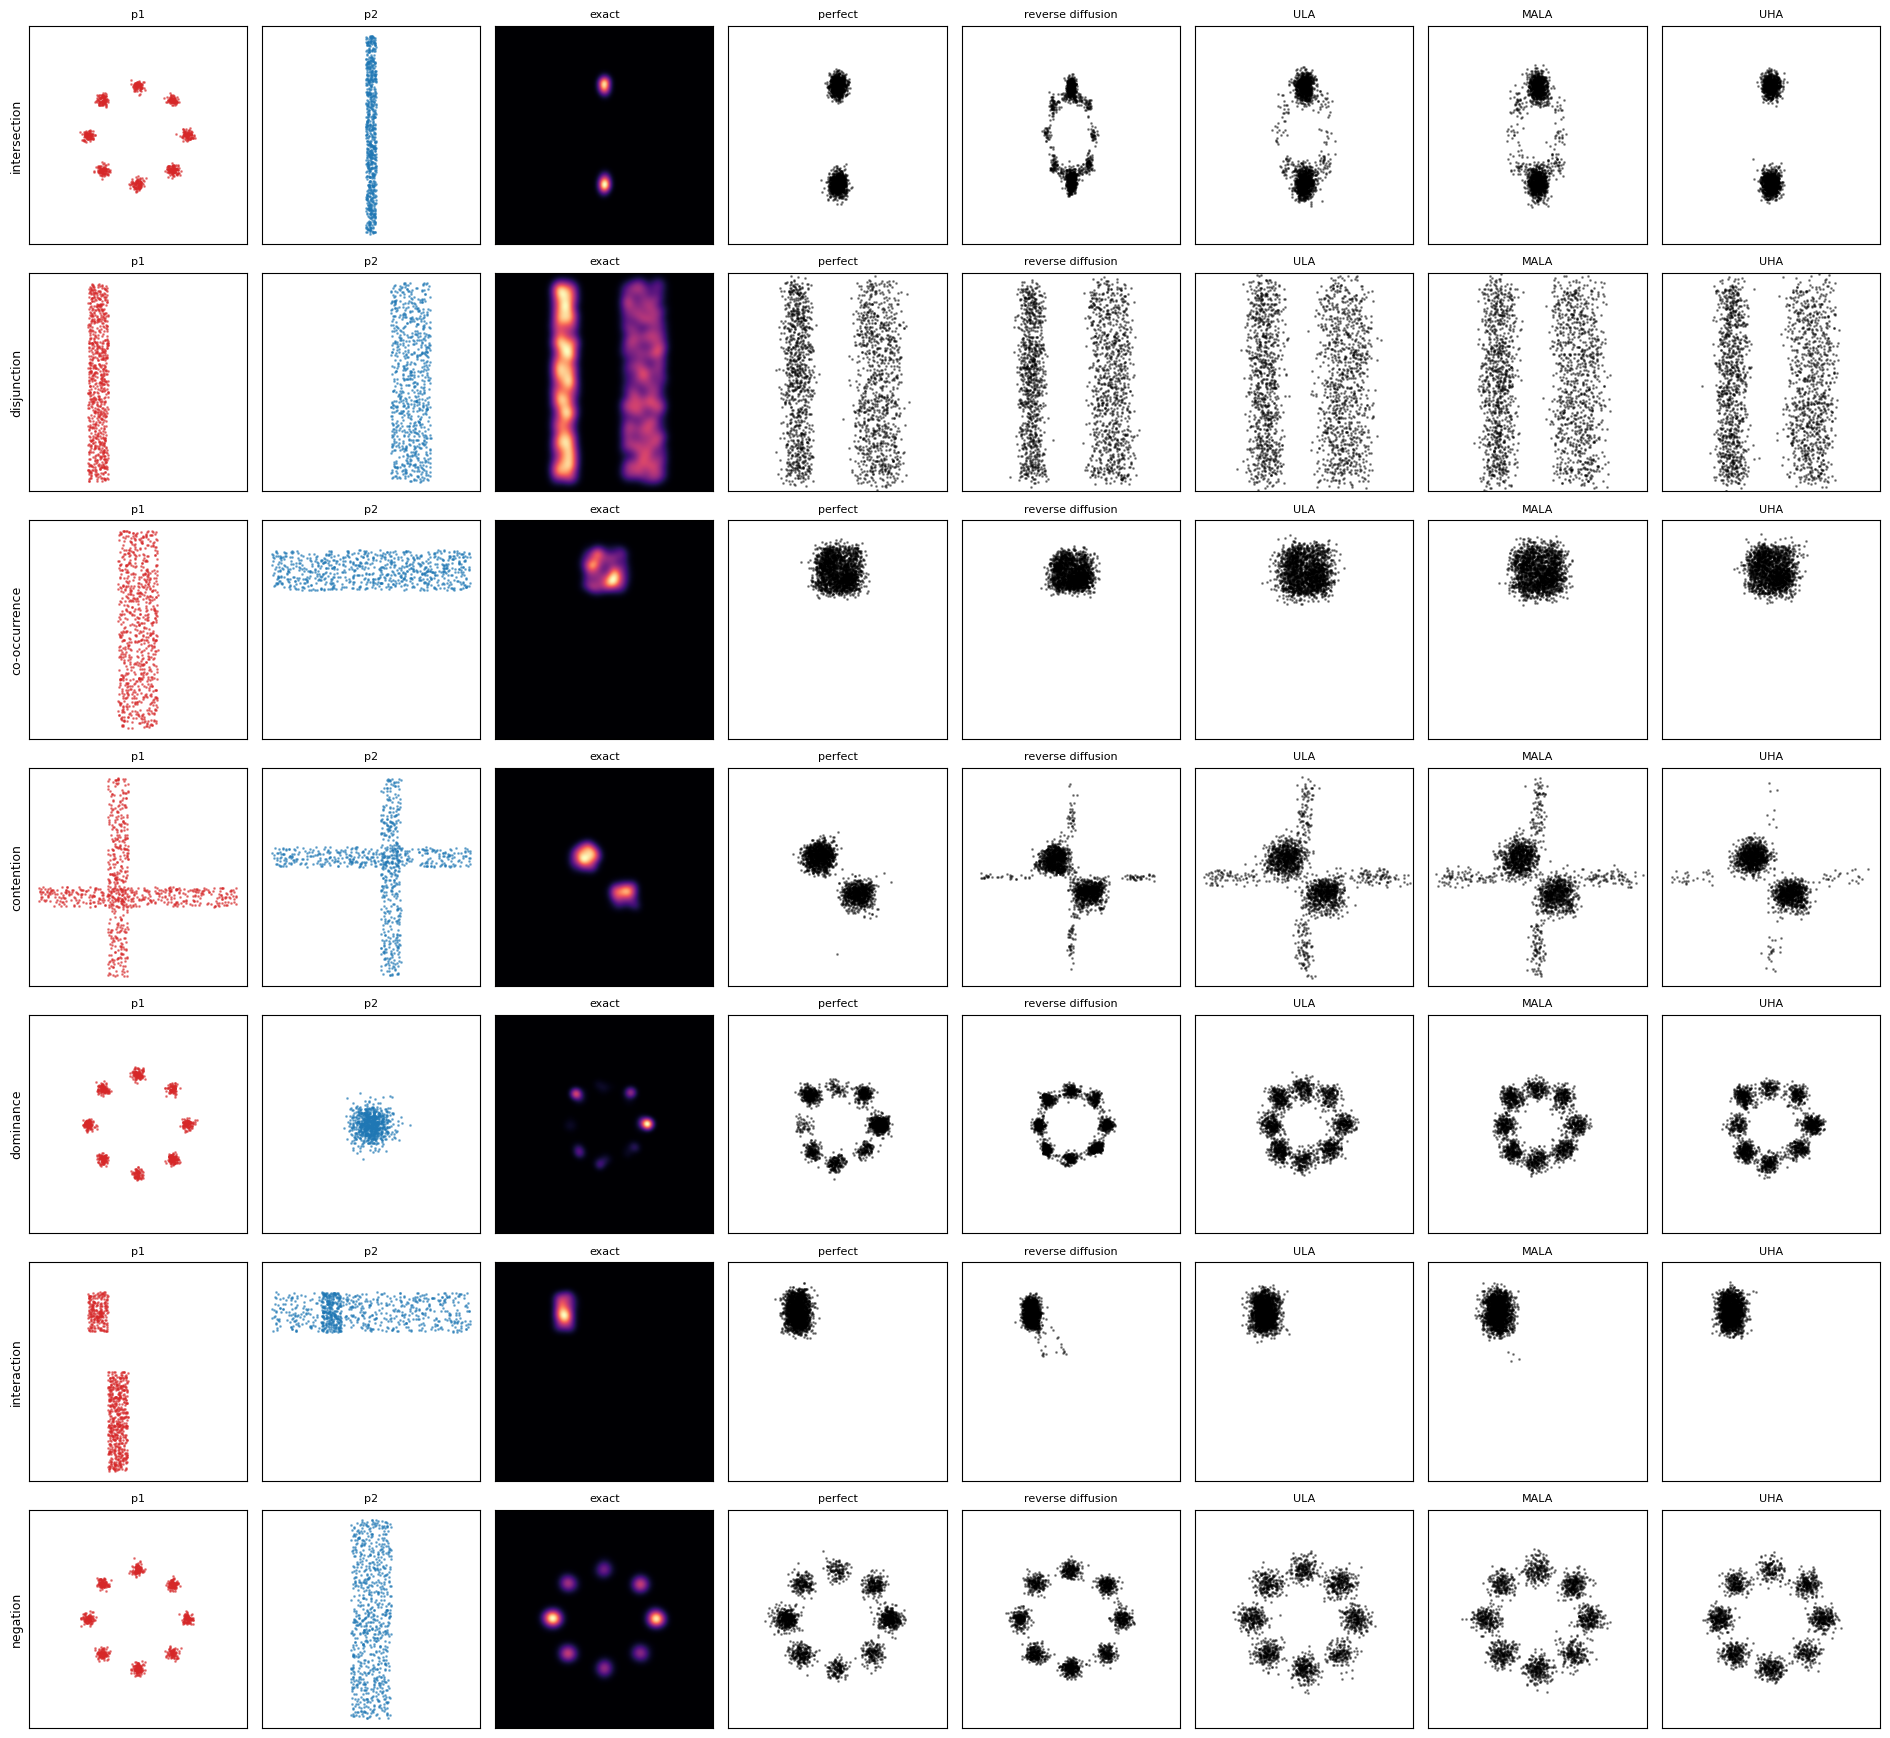

MALA acceptance: {'intersection': 0.99, 'disjunction': 1.0, 'co-occurrence': 1.0, 'contention': 1.0, 'dominance': 0.99, 'interaction': 1.0, 'negation': 1.0}
          kind |  exact |           perfect | reverse diffusion |               ULA |              MALA |               UHA   (measure / TV)
  intersection |   0.71 |     0.71 / 0.11 |     0.62 / 0.31 |     0.51 / 0.25 |     0.50 / 0.24 |     0.66 / 0.13
   disjunction |   0.50 |     0.51 / 0.23 |     0.50 / 0.21 |     0.52 / 0.24 |     0.50 / 0.24 |     0.49 / 0.23
 co-occurrence |   0.81 |     0.81 / 0.10 |     0.92 / 0.19 |     0.72 / 0.13 |     0.71 / 0.15 |     0.80 / 0.10
    contention |   0.67 |     0.67 / 0.10 |     0.57 / 0.23 |     0.41 / 0.30 |     0.42 / 0.30 |     0.62 / 0.12
     dominance |   0.40 |     0.40 / 0.11 |     0.34 / 0.58 |     0.37 / 0.41 |     0.37 / 0.38 |     0.39 / 0.29
   interaction |  -0.41 |    -0.41 / 0.07 |    -0.40 / 0.30 |    -0.40 / 0.10 |    -0.40 / 0.09 |    -0.40 / 0.08
      negation |  

In [5]:
fig, ax = plt.subplots(len(KINDS), 8, figsize=(19, 2.5 * len(KINDS)))
for r, k in enumerate(KINDS):
    A, B = (d.cpu().numpy() for d in k["data"])
    for j, (d, c, n) in enumerate([(A, "tab:red", "p1"), (B, "tab:blue", "p2")]):
        ax[r, j].scatter(*d.T, s=1, c=c, alpha=.5); ax[r, j].set_title(n)
    ax[r, 0].set_ylabel(k["name"], fontsize=9)
    ax[r, 2].imshow(k["p"], origin="lower", extent=[-L, L, -L, L], cmap="magma")
    ax[r, 2].set_title("exact")
    for j, c in enumerate(COLS, start=3):
        s = k["samples"][c]; row = next(x for x in results if x["kind"] == k["name"] and x["sampler"] == c)
        ax[r, j].scatter(*s.T, s=1, c="k", alpha=.4)
        ax[r, j].set_title(c)
    for a in ax[r]:
        a.set_xlim(-L, L); a.set_ylim(-L, L); a.set_aspect("equal"); a.set_xticks([]); a.set_yticks([])
plt.tight_layout(); plt.show()

print("MALA acceptance:", {k["name"]: round(k["accept"], 2) for k in KINDS})
print(f"{'kind':>14} | {'exact':>6} | " + " | ".join(f"{c:>17}" for c in COLS) + "   (measure / TV)")
for k in KINDS:
    rows = [next(x for x in results if x["kind"] == k["name"] and x["sampler"] == c) for c in COLS]
    print(f"{k['name']:>14} | {k['exact']:>6.2f} | " + " | ".join(f"{x['measure']:>8.2f} / {x['tv']:.2f}" for x in rows))

In [6]:
# dominance: is the excess TV about how mass is shared between the 8 modes, or about each mode's width?
k = KINDS[4]
ang = np.arctan2(X2, X1); sector = np.round(ang / (np.pi / 4)).astype(int) % 8
exact_share = np.array([(k["p"] * cell * (sector == m)).sum() for m in range(8)])
def share(s):
    sec = np.round(np.arctan2(s[:, 1], s[:, 0]) / (np.pi / 4)).astype(int) % 8
    return np.bincount(sec, minlength=8) / len(s)
def width(s):   # mean distance of each sample to its nearest ring mode
    return np.min(np.hypot(s[:, :1] - RING[:, 0], s[:, 1:] - RING[:, 1]), 1).mean()
gx, gy = X1.ravel(), X2.ravel(); w = (k["p"] * cell).ravel()
exact_width = (w * np.min(np.hypot(gx[:, None] - RING[:, 0], gy[:, None] - RING[:, 1]), 1)).sum() / w.sum()
print("share of mass per mode, modes 0..7 counter-clockwise from the right")
print(f"{'exact':>18}", np.round(exact_share, 2), f"| mean distance to nearest mode {exact_width:.3f}")
for c in COLS:
    s = k["samples"][c]
    print(f"{c:>18}", np.round(share(s), 2), f"| mean distance to nearest mode {width(s):.3f}")

share of mass per mode, modes 0..7 counter-clockwise from the right
             exact [0.35 0.13 0.04 0.2  0.03 0.1  0.09 0.06] | mean distance to nearest mode 0.110
           perfect [0.36 0.13 0.04 0.19 0.03 0.09 0.09 0.07] | mean distance to nearest mode 0.111
 reverse diffusion [0.12 0.09 0.12 0.14 0.16 0.13 0.1  0.14] | mean distance to nearest mode 0.162
               ULA [0.12 0.09 0.11 0.14 0.14 0.16 0.1  0.13] | mean distance to nearest mode 0.150
              MALA [0.12 0.11 0.11 0.15 0.12 0.14 0.12 0.12] | mean distance to nearest mode 0.147
               UHA [0.17 0.11 0.08 0.16 0.08 0.16 0.12 0.12] | mean distance to nearest mode 0.129


**Reading it.** TV is read against the perfect column, the floor 2,000 points reach with no sampler error (`0.07` to `0.23` depending on how spread out the target is).

**Annealed UHA is closest to the floor on every kind.** It sits within `0.02` of the floor on intersection, disjunction, co-occurrence, contention and interaction. Its worst rows are dominance (`0.29` against a floor of `0.11`) and negation (`0.21` against `0.15`).

**Reverse diffusion with the composed score fails as Du et al. predict, except on disjunction.** On intersection it leaves a faint ring of samples between the two true modes (TV `0.31`, floor `0.11`). On co-occurrence it pulls the patch inward (mass in the crossing `0.92` against the exact `0.81`). On interaction it gets the mean right (`−0.40`) but the shape wrong (TV `0.30`, floor `0.07`). On negation it doubles the mass left on the in-bar modes (`0.20` against `0.10`). Disjunction is the exception (TV `0.21`, floor `0.23`): a mixture of noised densities is exactly the noised mixture, so the composed score is the right score there.

**ULA and MALA give the same numbers because MALA accepted `0.99` to `1.00` of its proposals.** At step size `0.05·v_t` the accept step almost never fires, so this is not yet a test of what the accept step buys. Both leave stragglers on the ring (intersection) and along the bars' arms (contention), which is slow mixing at small steps.

**Dominance is where every sampler fails, and the cell above says why.** The exact product gives the right-hand mode `0.35` of its mass and the others between `0.03` and `0.20`. Reverse diffusion, ULA and MALA give every mode close to an even eighth (`0.09` to `0.16`), and UHA only partly recovers the imbalance (`0.17` on the right-hand mode). The samplers' clusters also sit further from the true, inward-pulled modes (mean distance `0.13` to `0.16`, against the exact `0.11`). The scatter panels hide the weights because the dots saturate, so the numbers are the evidence here. Moving mass between well-separated modes needs moves that local samplers do not make. Negation's excess TV looks the same way: the exact composition weights the left and right modes more than the samplers do, which has not been measured mode by mode.

## Figure 2: the condition that decides each kind

The exact composition's success measure against one dial, for the four kinds where a condition decides the outcome. No sampler is involved: these curves are what a perfect sampler would reach.

- **co-occurrence:** how far A's vertical bar reaches into B's band (its top edge; the band starts at `0.4`)
- **contention:** the share of each training set rotated so the object appears in the other slot
- **interaction:** the share of training points showing A as it looks under B
- **negation:** the negation weight $w$, with the share of mass away from every ring mode beside it

co-occurrence {1.0: np.float64(0.796), 0.8: np.float64(0.818), 0.6: np.float64(0.847), 0.5: np.float64(0.718), 0.4: np.float64(0.481), 0.3: np.float64(0.116)}
contention {0.5: np.float64(0.694), 0.3: np.float64(0.664), 0.2: np.float64(0.685), 0.1: np.float64(0.684), 0.05: np.float64(0.657), 0.0: np.float64(0.002)}


interaction {0.3: np.float64(-0.396), 0.2: np.float64(-0.394), 0.1: np.float64(-0.4), 0.05: np.float64(-0.39), 0.02: np.float64(-0.394), 0.0: np.float64(-0.215)}


negation in-bar {0.0: np.float64(0.146), 0.02: np.float64(0.121), 0.05: np.float64(0.085), 0.1: np.float64(0.037), 0.3: np.float64(0.0), 1.0: np.float64(0.0)} away {0.0: np.float64(0.387), 0.02: np.float64(0.384), 0.05: np.float64(0.391), 0.1: np.float64(0.439), 0.3: np.float64(0.863), 1.0: np.float64(1.0)}


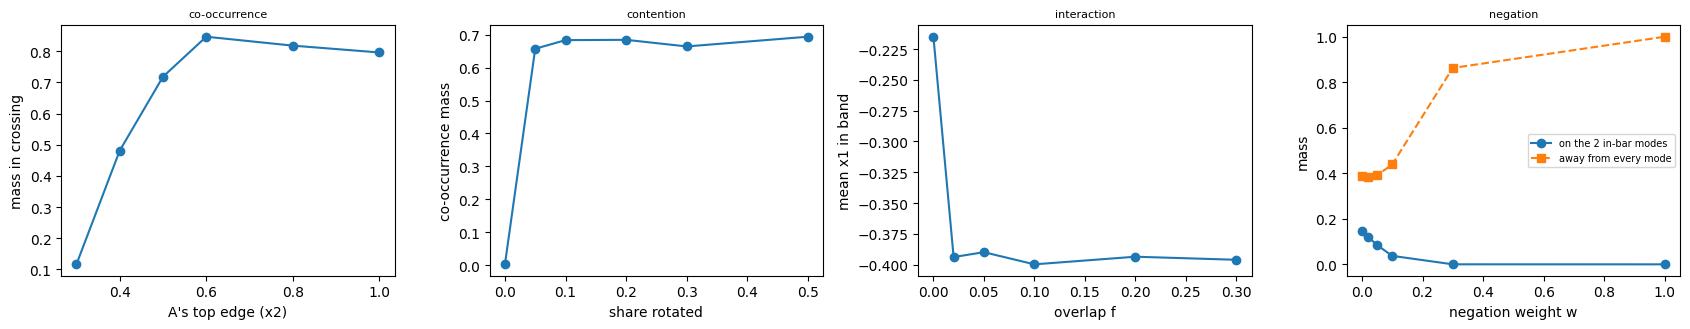

In [7]:
def exact_measure(A, B, compose, measure):
    k = dict(data=(tt(A), tt(B)), compose=compose); p = exact_grid(k)
    return measure(X1, X2, p * cell), p

dials = {
 "co-occurrence": ([1.0, 0.8, 0.6, 0.5, 0.4, 0.3], "A's top edge (x2)", lambda v: (vbar(N, 0.0, 0.2, -1.0, v), hbar(N, 0.6)), KINDS[2]),
 "contention": ([0.5, 0.3, 0.2, 0.1, 0.05, 0.0], "share rotated", lambda v: (rotated(-0.2, N, v), rotated(0.2, N, v)), KINDS[3]),
 "interaction": ([0.3, 0.2, 0.1, 0.05, 0.02, 0.0], "overlap f", lambda v: wet_dog(v), KINDS[5]),
}
fig, ax = plt.subplots(1, 4, figsize=(17, 3.4))
for a, (name, (vals, label, make, kind)) in zip(ax, dials.items()):
    ms = [exact_measure(*make(v), kind["compose"], kind["measure"])[0] for v in vals]
    a.plot(vals, ms, "o-"); a.set_xlabel(label); a.set_ylabel(kind["mname"]); a.set_title(name)
    print(name, dict(zip(vals, np.round(ms, 3))))
ws = [0.0, 0.02, 0.05, 0.1, 0.3, 1.0]; ring, bar = toy_gmm(N), vbar(N, 0.0, 0.2)
far = lambda a, b, w: (w * ~near(a, b, RING, 0.08)).sum()
inbar, away = [], []
for w in ws:
    m, p = exact_measure(ring, bar, lambda a, b, w=w: (1 + w) * a - w * b, KINDS[6]["measure"])
    inbar.append(m); away.append(far(X1, X2, p * cell))
ax[3].plot(ws, inbar, "o-", label="on the 2 in-bar modes"); ax[3].plot(ws, away, "s--", label="away from every mode")
ax[3].set_xlabel("negation weight w"); ax[3].set_ylabel("mass"); ax[3].set_title("negation"); ax[3].legend(fontsize=7)
print("negation in-bar", dict(zip(ws, np.round(inbar, 3))), "away", dict(zip(ws, np.round(away, 3))))
plt.tight_layout(); plt.show()

**Reading it.** These are the exact curves, with no sampler involved, and they repeat the earlier finding with fresh data draws. Co-occurrence holds at `0.80` to `0.85` while A's bar reaches into B's band, and falls to `0.12` when it stops `0.1` short. Contention is a step: `0.002` with no rotation, `0.66` with 5%. Interaction reaches the wet position (`−0.39`) at 2% overlap. Negation removes the in-bar modes only as fast as it creates mass away from every mode: at the paper's `w = 0.3`, `0.86` of the mass is off the ring.

**Where Figure 1 and Figure 2 meet.** Figure 1 ran each kind at a setting deep inside its success region. The settings where samplers and data could be confused are the steep parts of these curves: co-occurrence at a top edge of `0.4`, contention at 5% rotated, interaction at 2%. That is where a sampler row should be added next.

## Run 1: MALA with steps large enough for its accept step to matter

In Figure 1, MALA accepted `0.99` to `1.00` of its proposals, so it behaved like ULA. Here MALA's step size adapts at every noise level, multiplying by $e^{(\text{acceptance} - 0.6)}$ after each move, so it settles near 60% acceptance. ULA then runs with exactly the same per-level step sizes, so **the accept step is the only difference between the two columns.**

The adaptation happens during the run, so the chain is not exactly reversible while it adapts. That is acceptable for asking how large the steps can be. A final, fixed-step run would remove it.

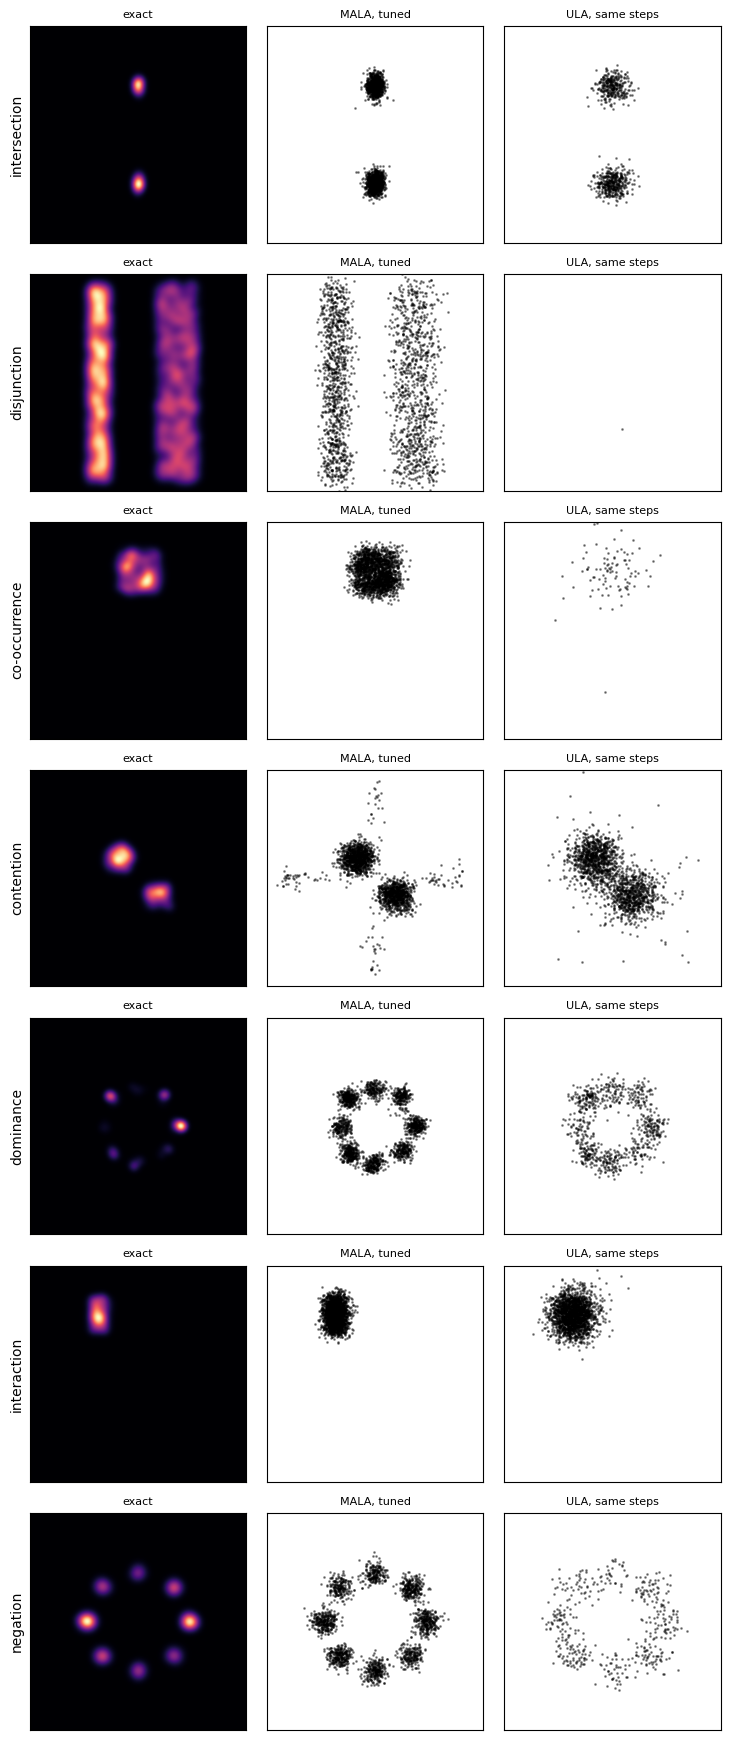

          kind | accept | final step / Figure 1 step | TV MALA tuned | TV ULA same steps (samples kept) | TV MALA Figure 1 | floor
  intersection | 0.60   |     18.6x                   | 0.11          | 0.38 (721)                  | 0.24             | 0.11
   disjunction | 0.61   |     82.4x                   | 0.22          | 1.00 (1)                  | 0.24             | 0.23
 co-occurrence | 0.61   |     68.9x                   | 0.11          | 0.45 (157)                  | 0.15             | 0.10
    contention | 0.60   |     43.9x                   | 0.16          | 0.39 (1843)                  | 0.30             | 0.10
     dominance | 0.60   |     17.6x                   | 0.30          | 0.47 (777)                  | 0.38             | 0.11
   interaction | 0.61   |     37.5x                   | 0.08          | 0.33 (2000)                  | 0.09             | 0.07
      negation | 0.60   |     28.7x                   | 0.21          | 0.50 (446)                  | 0.25       

In [8]:
def annealed_mala_adaptive(kind, k=10, target=0.6):
    x = torch.randn(NS, 2, device=dev); acc, steps = [], []
    ss = 0.05 * V[0]
    for i, t in enumerate(LEVELS):
        f, g = energy_fn(kind, t), grad_fn(kind, t)
        ss = max(ss, 0.05 * V[i]) if i == 0 else ss * V[i] / V[i - 1]     # carry the step across levels, scaled by the variance
        e, gr = f(x).detach(), g(x); lvl = []
        for _ in range(k):
            xp = x + ss * gr + np.sqrt(2 * ss) * torch.randn_like(x)
            ep, gp = f(xp).detach(), g(xp)
            fwd = -((xp - x - ss * gr) ** 2).sum(1) / (4 * ss)
            bwd = -((x - xp - ss * gp) ** 2).sum(1) / (4 * ss)
            a = (torch.log(torch.rand(NS, device=dev)) < ep - e + bwd - fwd)
            x, e, gr = torch.where(a[:, None], xp, x), torch.where(a, ep, e), torch.where(a[:, None], gp, gr)
            r = a.float().mean().item(); lvl.append(r); ss *= float(np.exp(r - target))
        acc.append(np.mean(lvl)); steps.append(ss)
    return x.cpu().numpy(), float(np.mean(acc[-10:])), steps

run1 = []
fig, ax = plt.subplots(len(KINDS), 3, figsize=(7.5, 2.5 * len(KINDS)))
for r, k in enumerate(KINDS):
    xm, am, steps = annealed_mala_adaptive(k)
    gfun = lambda x, ts, k=k: grad_fn(k, ts)(x)
    s = AnnealedULASampler(T, 10, steps, gfun); xu = torch.randn(NS, 2, device=dev)
    for i, t in enumerate(LEVELS): xu = s.sample_step(xu, i, t, {})
    xu = xu.cpu().numpy(); xu = xu[np.isfinite(xu).all(1)]
    old = next(x for x in results if x["kind"] == k["name"] and x["sampler"] == "MALA")
    floor = next(x for x in results if x["kind"] == k["name"] and x["sampler"] == "perfect")
    run1.append(dict(kind=k["name"], accept=am, step_ratio=steps[-1] / (0.05 * V[-1]),
                     tv_mala=tv(xm, k["p"]), tv_ula_same=tv(xu, k["p"]) if len(xu) else float("nan"),
                     ula_kept=len(xu), tv_mala_small=old["tv"], floor=floor["tv"]))
    ax[r, 0].imshow(k["p"], origin="lower", extent=[-L, L, -L, L], cmap="magma"); ax[r, 0].set_title("exact"); ax[r, 0].set_ylabel(k["name"])
    ax[r, 1].scatter(*xm.T, s=1, c="k", alpha=.4); ax[r, 1].set_title("MALA, tuned")
    ax[r, 2].scatter(*xu.T, s=1, c="k", alpha=.4); ax[r, 2].set_title("ULA, same steps")
    for a in ax[r]: a.set_xlim(-L, L); a.set_ylim(-L, L); a.set_aspect("equal"); a.set_xticks([]); a.set_yticks([])
plt.tight_layout(); plt.show()
print(f"{'kind':>14} | accept | final step / Figure 1 step | TV MALA tuned | TV ULA same steps (samples kept) | TV MALA Figure 1 | floor")
for x in run1:
    print(f"{x['kind']:>14} | {x['accept']:.2f}   | {x['step_ratio']:>8.1f}x                   | {x['tv_mala']:.2f}          | {x['tv_ula_same']:.2f} ({x['ula_kept']})                  | {x['tv_mala_small']:.2f}             | {x['floor']:.2f}")

**Reading it.** Tuned MALA settled at `0.60` acceptance with steps `18` to `82` times larger than in Figure 1. At those steps it reaches the perfect-sampler floor on intersection (TV `0.11`, floor `0.11`), disjunction (`0.22`, `0.23`), co-occurrence (`0.11`, `0.10`) and interaction (`0.08`, `0.07`). It stays above the floor on contention (`0.16`, `0.10`), negation (`0.21`, `0.15`) and dominance (`0.30`, `0.11`), so the dominance mode-weight failure survives the larger steps.

**ULA at the same steps falls apart.** Some of its samples run off to infinity and are dropped: it keeps `1` of 2,000 on disjunction, `157` on co-occurrence and `446` on negation. Where it survives, its TV is `0.33` to `0.50`. **The accept step is what makes the large steps safe, and the large steps are what let MALA mix.** At Figure 1's small steps the accept step had nothing to do, which is why MALA and ULA looked identical there.

## Run 2: the samplers at the steep points of Figure 2

Figure 1 ran every kind deep inside its success region. Here three kinds run at the setting where Figure 2's curve is steepest, the place where a sampler's error and the data's limit could be mistaken for each other:

- **co-occurrence** with A's top edge at `0.4`: A's bar just touches B's band, and the exact mass in the crossing is about `0.48`
- **contention** with 5% of each set rotated: just past the step from chimera to co-occurrence
- **interaction** at 2% overlap: just past the step from dry to wet

The question for each row: does a sampler report more success, or less, than the exact composition says the data allows?

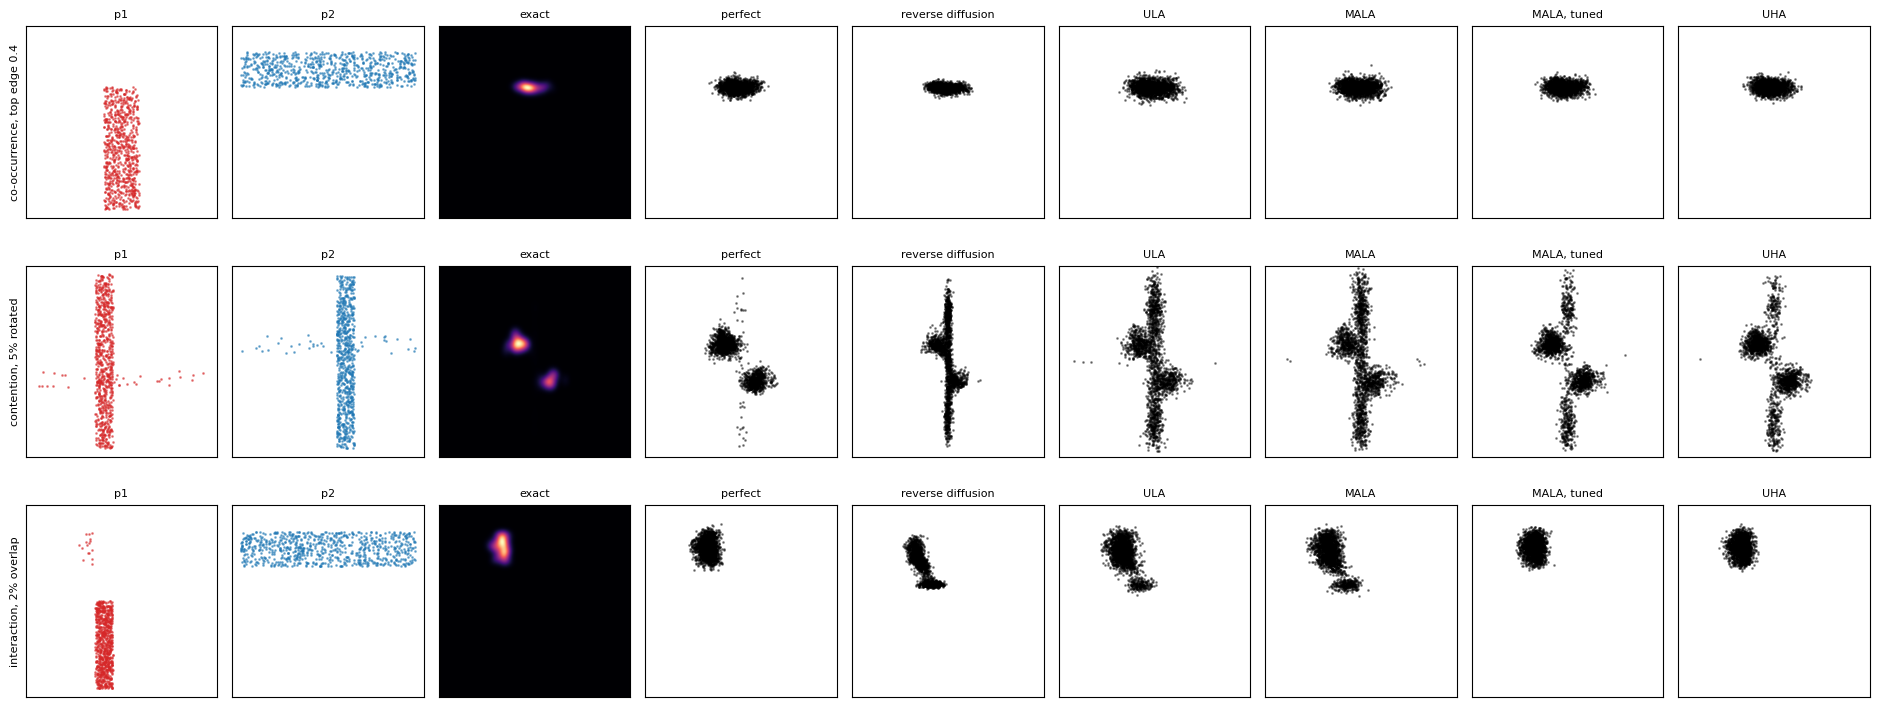

co-occurrence, top edge 0.4 (mass in crossing), exact 0.44
              perfect: 0.43 · TV 0.11
    reverse diffusion: 0.38 · TV 0.22
                  ULA: 0.40 · TV 0.19
                 MALA: 0.42 · TV 0.18
          MALA, tuned: 0.42 · TV 0.13
                  UHA: 0.43 · TV 0.13
contention, 5% rotated (co-occurrence mass), exact 0.75
              perfect: 0.73 · TV 0.10
    reverse diffusion: 0.21 · TV 0.69
                  ULA: 0.26 · TV 0.57
                 MALA: 0.24 · TV 0.57
          MALA, tuned: 0.53 · TV 0.30
                  UHA: 0.53 · TV 0.27
interaction, 2% overlap (mean x1 in band), exact -0.38
              perfect: -0.38 · TV 0.05
    reverse diffusion: -0.35 · TV 0.59
                  ULA: -0.37 · TV 0.26
                 MALA: -0.37 · TV 0.27
          MALA, tuned: -0.38 · TV 0.08
                  UHA: -0.38 · TV 0.08


In [9]:
STEEP = [dict(KINDS[2], name="co-occurrence, top edge 0.4", data=(tt(vbar(N, 0.0, 0.2, -1.0, 0.4)), tt(hbar(N, 0.6)))),
         dict(KINDS[3], name="contention, 5% rotated", data=(tt(rotated(-0.2, N, 0.05)), tt(rotated(0.2, N, 0.05)))),
         dict(KINDS[5], name="interaction, 2% overlap", data=tuple(tt(d) for d in wet_dog(0.02)))]
COLS2 = ["perfect", "reverse diffusion", "ULA", "MALA", "MALA, tuned", "UHA"]
rows2 = []
fig, ax = plt.subplots(len(STEEP), 3 + len(COLS2), figsize=(2.1 * (3 + len(COLS2)), 2.5 * len(STEEP)))
for r, k in enumerate(STEEP):
    p = exact_grid(k); k["p"] = p; ex = k["measure"](X1, X2, p * cell)
    S = {"perfect": perfect_samples(p), "reverse diffusion": reverse_diffusion(k), "ULA": annealed(k, "ULA"),
         "MALA": annealed_mala(k)[0], "MALA, tuned": annealed_mala_adaptive(k)[0], "UHA": annealed(k, "UHA")}
    A, B = (d.cpu().numpy() for d in k["data"])
    ax[r, 0].scatter(*A.T, s=1, c="tab:red", alpha=.5); ax[r, 0].set_title("p1"); ax[r, 0].set_ylabel(k["name"], fontsize=8)
    ax[r, 1].scatter(*B.T, s=1, c="tab:blue", alpha=.5); ax[r, 1].set_title("p2")
    ax[r, 2].imshow(p, origin="lower", extent=[-L, L, -L, L], cmap="magma"); ax[r, 2].set_title("exact")
    for j, c in enumerate(COLS2, start=3):
        s = S[c]; ax[r, j].scatter(*s.T, s=1, c="k", alpha=.4); ax[r, j].set_title(c)
        rows2.append(dict(kind=k["name"], sampler=c, exact=float(ex), tv=float(tv(s, p)),
                          measure=float(k["measure"](s[:, 0], s[:, 1], np.full(len(s), 1 / len(s))))))
    for a in ax[r]: a.set_xlim(-L, L); a.set_ylim(-L, L); a.set_aspect("equal"); a.set_xticks([]); a.set_yticks([])
plt.tight_layout(); plt.show()
for k in STEEP:
    rs = [x for x in rows2 if x["kind"] == k["name"]]
    print(f"{k['name']} ({k['mname']}), exact {rs[0]['exact']:.2f}")
    for x in rs: print(f"    {x['sampler']:>17}: {x['measure']:.2f} · TV {x['tv']:.2f}")

**Reading it.** Co-occurrence at the edge is easy for every sampler: the exact mass in the crossing is `0.44` and the samplers give `0.38` to `0.43`.

**Contention at 5% rotated is where a sampler invents a failure.** The exact composition puts `0.75` of its mass on co-occurrence, because 5% of position variation is enough in the data. Reverse diffusion gives `0.21`: its samples form a single column at $x_1 \approx 0$, between the bars, which is a chimera the exact composition does not contain (TV `0.69`). ULA and MALA at Figure 1's steps give `0.26` and `0.24`. Tuned MALA and UHA recover half the gap (`0.53`, TV `0.30` and `0.27`).

**Interaction at 2% overlap shows the same thing.** The exact composition sits at the wet position (`−0.38`). Reverse diffusion, ULA and MALA put a second cluster at the dry position at the bottom edge of the band (TV `0.59`, `0.26`, `0.27`), which looks like a missing interaction. Tuned MALA and UHA match the exact composition (TV `0.08`, floor `0.05`).

**Near the edge of what the data supports, a weak sampler draws the failure picture of the kind**: a chimera for contention, a dry dog for interaction. Read without the exact composition beside it, that picture would be blamed on missing data.

## What this notebook cannot show

- **Ideal experts only.** A trained network matched them in 2D (run 2). On images it may extrapolate, which no panel here can show.
- **One step-size setting per sampler.** A sampler that fails here might pass with tuning. The step sizes are stated above so the comparison can be rerun.
- **Leakage is missing.** It needs two attributes per object.